<a href="https://colab.research.google.com/github/sashawrk4-pylyp/SQL-Analysis-Email-Campaign-Performance-and-Account-Metrics/blob/main/4_Data_Visualization_with_Matplotlib.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [53]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [54]:
# Connecting Google Drive
from google.colab import drive
drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [55]:
# Changing work folder
%cd /content/drive/MyDrive/**Jupyter**

[Errno 2] No such file or directory: '/content/drive/MyDrive/**Jupyter**'
/content


In [56]:
!find /content/drive/MyDrive/Jupyter -iname "*sales*"

/content/drive/MyDrive/Jupyter/sales_data_updated.gsheet
/content/drive/MyDrive/Jupyter/sales_data_updated - sales_data_updated.csv
/content/drive/MyDrive/Jupyter/sales.csv
/content/drive/MyDrive/Jupyter/sales_data.csv
/content/drive/MyDrive/Jupyter/sales3.ipynb
/content/drive/MyDrive/Jupyter/books_sales.ipynb
/content/drive/MyDrive/Jupyter/Online store sales.ipynb
/content/drive/MyDrive/Jupyter/Online store sales2
/content/drive/MyDrive/Jupyter/restaurant_sales.csv
/content/drive/MyDrive/Jupyter/Sales Comparison


In [57]:
# Завантаження CSV-файлу
seles_data = pd.read_csv("/content/drive/MyDrive/Jupyter/sales_data_updated - sales_data_updated.csv")

# Перегляд перших рядків
seles_data.head()

,order_date,time,aging,customer_id,gender,device_type,customer_login_type,product_category,product,sales,quantity,discount,profit,shipping_cost,order_priority,payment_method
0,2018-01-01,10:11:40,5.0,29317,Male,Web,Member,Auto & Accessories,Car Media Players,140.0,4.0,0.3,43.2,4.3,Medium,e_wallet
1,2018-01-01,22:30:44,7.0,42270,Male,Web,Member,Auto & Accessories,Car Pillow & Neck Rest,231.0,5.0,0.1,139.5,13.9,High,money_order
2,2018-01-01,21:55:31,10.0,14563,Male,Web,Member,Auto & Accessories,Car Speakers,211.0,5.0,0.1,120.5,12.0,High,credit_card
3,2018-01-01,13:57:15,9.0,58601,Male,Web,Member,Auto & Accessories,Tyre,250.0,4.0,0.2,150.0,15.0,Critical,credit_card
4,2018-01-01,15:17:41,2.0,48342,Male,Web,Member,Auto & Accessories,Tyre,250.0,1.0,0.1,165.0,16.5,High,credit_card


In [58]:
# Створення робочого DataFrame
df = sales_data.copy()

# Перетворення дати на формат datetime
df["order_date"] = pd.to_datetime(df["order_date"])

# Перегляд інформації про дані
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51290 entries, 0 to 51289
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   order_date           51290 non-null  datetime64[ns]
 1   time                 51290 non-null  object        
 2   aging                51289 non-null  float64       
 3   customer_id          51290 non-null  int64         
 4   gender               51290 non-null  object        
 5   device_type          51290 non-null  object        
 6   customer_login_type  51290 non-null  object        
 7   product_category     51290 non-null  object        
 8   product              51290 non-null  object        
 9   sales                51289 non-null  float64       
 10  quantity             51288 non-null  float64       
 11  discount             51289 non-null  float64       
 12  profit               51290 non-null  float64       
 13  shipping_cost        51289 non-

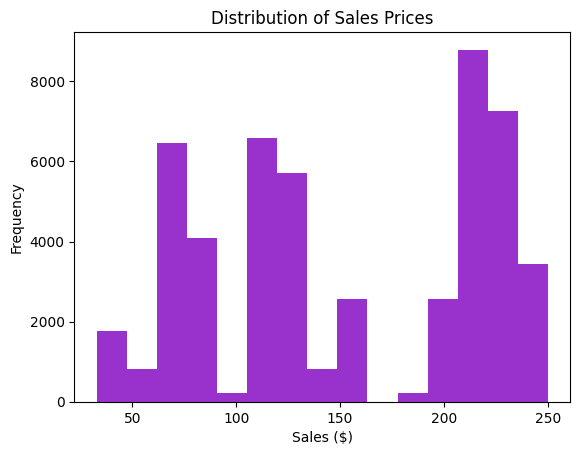

In [59]:
plt.hist(df["sales"], bins=15, color="darkorchid")
plt.title("Distribution of Sales Prices")
plt.xlabel("Sales ($)")
plt.ylabel("Frequency")
plt.show()

Розподіл сум продажів є нерівномірним. Найбільша кількість значень припадає на діапазон 200–230 доларів, також помітна значна частота в декількох інших діапазонах.

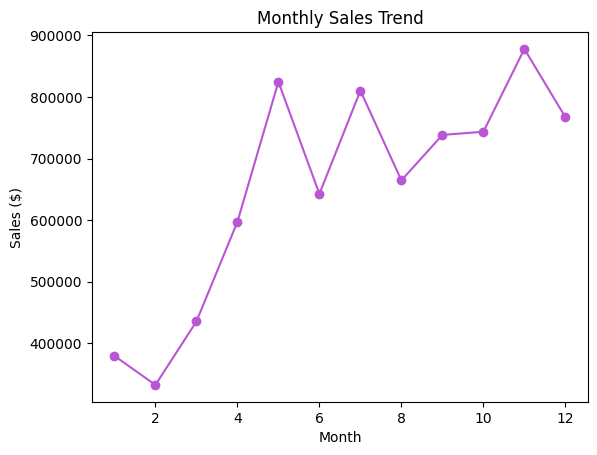

In [60]:
# Second subplot - Line plot
df["order_date"] = pd.to_datetime(df["order_date"])
sales_by_month = df.groupby(df["order_date"].dt.month)["sales"].sum()

plt.plot(sales_by_month.index, sales_by_month.values, marker="o", color="mediumorchid")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales ($)")
plt.show()

Протягом року обсяг продажів помітно коливається. Найвище значення спостерігається в листопаді та становить приблизно 880 тисяч доларів. Загалом простежується тенденція до зростання продажів.

Text(0, 0.5, 'Number of Orders')

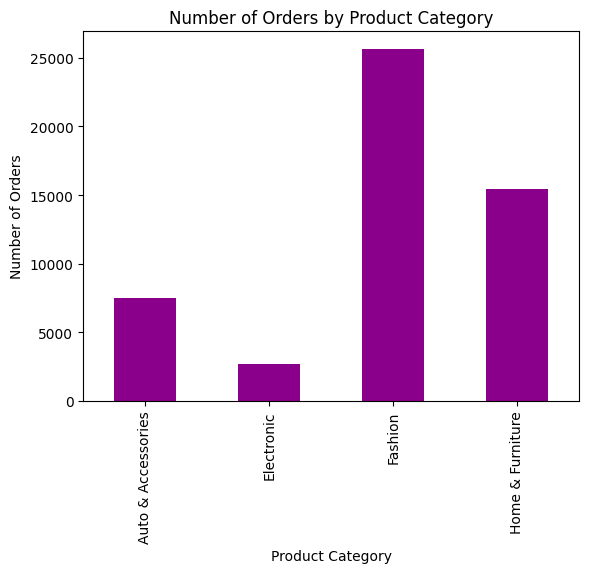

In [61]:
# Third subplot - Bar plot
df.groupby("product_category", observed=False).size().plot(kind="bar", color="darkmagenta")
plt.title("Number of Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Number of Orders")

Найбільша кількість замовлень припадає на категорію Fashion — приблизно 26 тисяч. Найменш популярною є категорія Electronic — близько 3 тисяч замовлень.

Text(0, 0.5, 'Sales ($)')

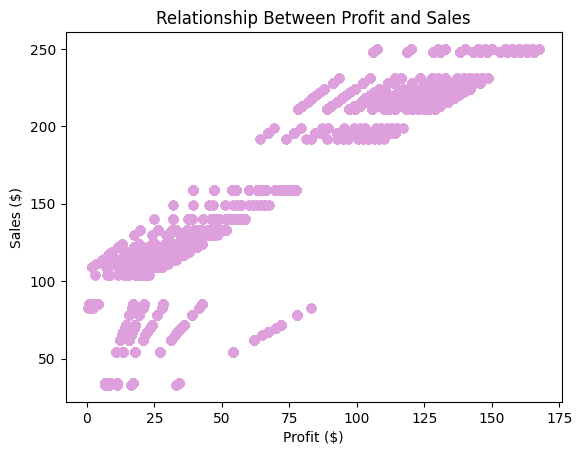

In [62]:
# Fourth subplot Scatter plot
plt.scatter(df["profit"], df["sales"], color="plum")
plt.title("Relationship Between Profit and Sales")
plt.xlabel("Profit ($)")
plt.ylabel("Sales ($)")

Між прибутком і продажами спостерігається позитивний взаємозв'язок: зі збільшенням суми продажів зазвичай зростає і прибуток. Водночас на графіку присутні окремі відхилення від загальної закономірності.

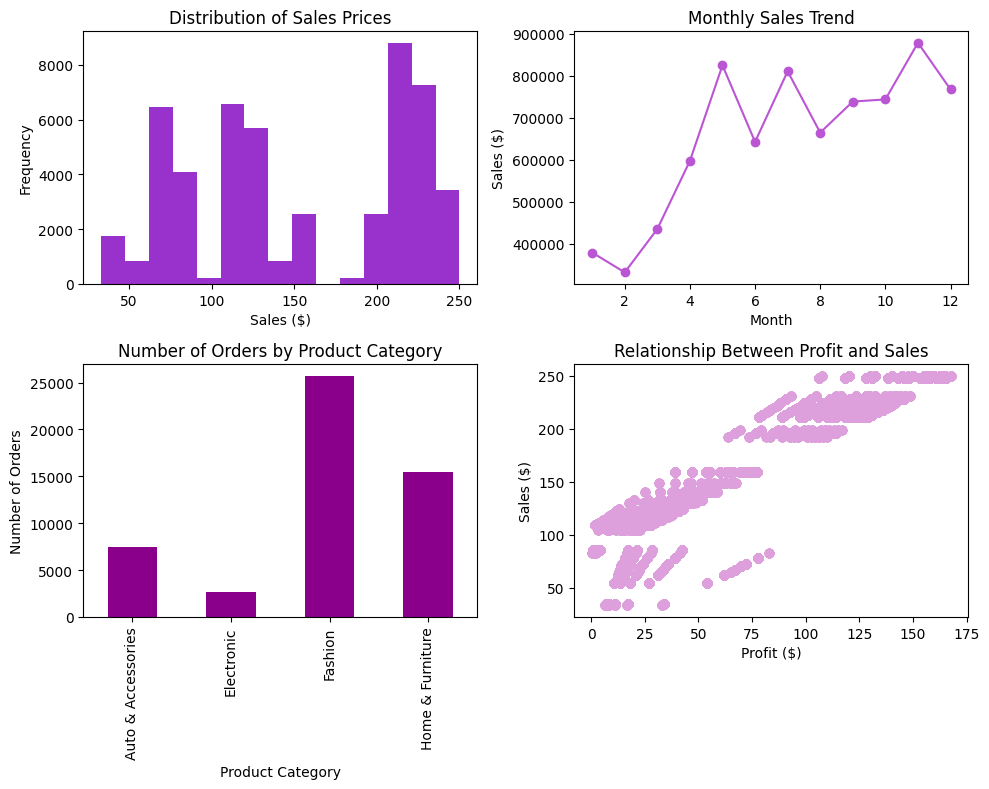

In [63]:
# Create a figure with 2 rows and 2 columns of subplots
fig, ax = plt.subplots(2, 2, figsize=(10, 8))

# First subplot - Histogram
ax[0, 0].hist(df["sales"], bins=15, color="darkorchid")
ax[0, 0].set_title("Distribution of Sales Prices")
ax[0, 0].set_xlabel("Sales ($)")
ax[0, 0].set_ylabel("Frequency")

# Second subplot - Line plot
df["order_date"] = pd.to_datetime(df["order_date"])
sales_by_month = df.groupby(df["order_date"].dt.month)["sales"].sum()

ax[0, 1].plot(sales_by_month.index, sales_by_month.values, marker="o", color="mediumorchid")
ax[0, 1].set_title("Monthly Sales Trend")
ax[0, 1].set_xlabel("Month")
ax[0, 1].set_ylabel("Sales ($)")

# Third subplot - Bar plot
df.groupby("product_category", observed=False).size().plot(kind="bar", ax=ax[1, 0], color="darkmagenta")
ax[1, 0].set_title("Number of Orders by Product Category")
ax[1, 0].set_xlabel("Product Category")
ax[1, 0].set_ylabel("Number of Orders")

# Fourth subplot Scatter plot
ax[1, 1].scatter(df["profit"], df["sales"], color="plum")
ax[1, 1].set_title("Relationship Between Profit and Sales")
ax[1, 1].set_xlabel("Profit ($)")
ax[1, 1].set_ylabel("Sales ($)")

# Adjust layout
plt.tight_layout()

# Show plots
plt.show()

Об'єднання чотирьох графіків дозволяє одночасно оцінити розподіл продажів, їхню динаміку, популярність товарних категорій та взаємозв'язок між прибутком і продажами. Такий формат полегшує загальний огляд даних.

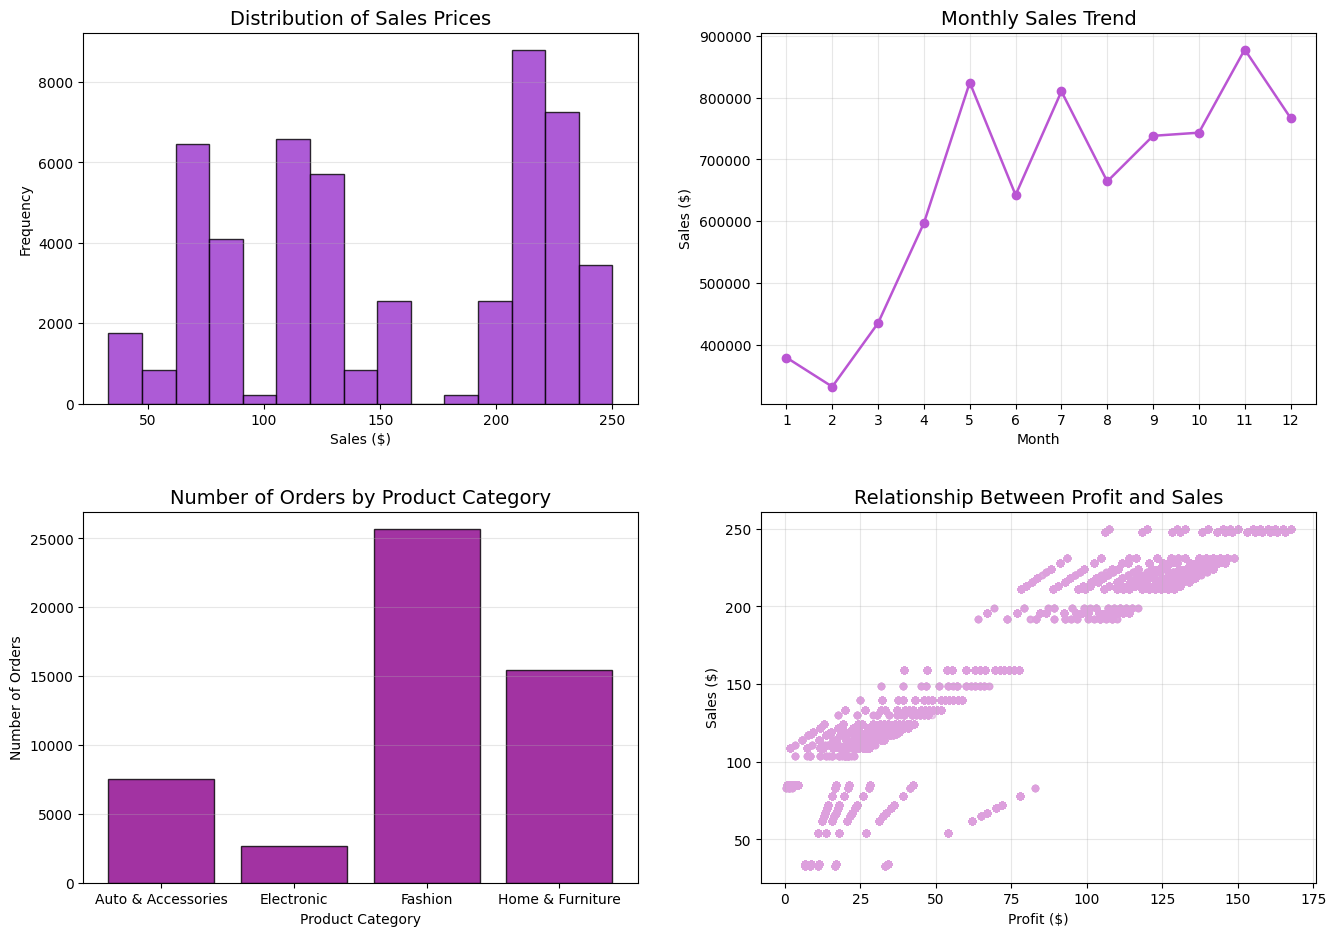

In [64]:
# Візуально покращений варіант
# Create a figure with 2 rows and 2 columns of subplots
fig, ax = plt.subplots(2, 2, figsize=(14, 10))

# First subplot - Histogram
ax[0, 0].hist(df["sales"], bins=15, color="darkorchid", edgecolor="black", alpha=0.8)
ax[0, 0].set_title("Distribution of Sales Prices", fontsize=14)
ax[0, 0].set_xlabel("Sales ($)")
ax[0, 0].set_ylabel("Frequency")
ax[0, 0].grid(axis="y", alpha=0.3)

# Second subplot - Line plot
df["order_date"] = pd.to_datetime(df["order_date"])
sales_by_month = df.groupby(df["order_date"].dt.month)["sales"].sum()

ax[0, 1].plot(sales_by_month.index, sales_by_month.values, marker="o", linewidth=1.8, color="mediumorchid")
ax[0, 1].set_title("Monthly Sales Trend", fontsize=14)
ax[0, 1].set_xlabel("Month")
ax[0, 1].set_ylabel("Sales ($)")
ax[0, 1].set_xticks(sales_by_month.index)
ax[0, 1].grid(alpha=0.3)

# Third subplot - Bar plot
category_counts = df.groupby("product_category", observed=False).size()
ax[1, 0].bar(category_counts.index, category_counts.values, color="darkmagenta", edgecolor="black", alpha=0.8)
ax[1, 0].set_title("Number of Orders by Product Category", fontsize=14)
ax[1, 0].set_xlabel("Product Category")
ax[1, 0].set_ylabel("Number of Orders")
ax[1, 0].grid(axis="y", alpha=0.3)

# Make category names readable
plt.setp(ax[1, 0].get_xticklabels(), rotation=0)

# Fourth subplot - Scatter plot
ax[1, 1].scatter(df["profit"], df["sales"], s=20, alpha=0.3, color="plum")
ax[1, 1].set_title("Relationship Between Profit and Sales", fontsize=14)
ax[1, 1].set_xlabel("Profit ($)")
ax[1, 1].set_ylabel("Sales ($)")
ax[1, 1].grid(alpha=0.3)

# Adjust layout
plt.tight_layout(pad=3)

# Show plots
plt.show()

Покращене оформлення графіків робить візуалізації більш зрозумілими та зручними для аналізу. Використання кольорів, сітки, чітких підписів і налаштування розмірів графіків покращує сприйняття інформації.